# 04 · Variograma y kriging: rellenar los vacíos que dejan las nubes

Aun con el compuesto por mediana, algunos hexágonos no tienen ninguna observación limpia en un
año. En lugar de descartarlos, se **predicen** con geoestadística:

1. Variograma empírico (Matheron): $\hat\gamma(h) = \frac{1}{2N(h)}\sum_{N(h)}[Z(s_i) - Z(s_j)]^2$
2. Ajuste de modelos teóricos (esférico, exponencial, gaussiano): pepita, meseta y rango.
3. Variogramas direccionales para revisar anisotropía (los ríos imponen una dirección).
4. **Kriging ordinario** con vecindario móvil, validado contra IDW.

In [0]:
%pip install -q rasterio pyproj h3 geopandas shapely esda libpysal spreg pykrige scikit-gstat mapclassify
dbutils.library.restartPython()

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Raíz del repositorio (Git folder en Databricks o clon local)
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

from geocloud import config as C, dbx
spark = dbx.get_spark()
VOL = dbx.volume_path()
FIG = Path(VOL) / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Databricks:", dbx.is_databricks(), "| Volume:", VOL)

Databricks: True | Volume: /Volumes/workspace/madre_dios_rs/raw


In [0]:
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from geocloud import spatial

feat = spark.table(dbx.tbl("gold_h3_features")).toPandas().pipe(dbx.clean)
YEARS = sorted(int(c.split("_")[1]) for c in feat.columns if c.startswith("ndvi_") and c.split("_")[1].isdigit())
Y0, Y1 = YEARS[0], YEARS[-1]
gdf = spatial.h3_to_geodataframe(feat, crs_out=C.CRS_UTM)
print(f"Hexágonos: {len(gdf):,} | años: {YEARS}")

Hexágonos: 21,854 | años: [2018, 2020, 2022, 2024, 2025]


In [0]:
VAR = f"ndvi_{Y1}"
obs = gdf.dropna(subset=[VAR]).reset_index(drop=True)
gaps = gdf[gdf[VAR].isna()].reset_index(drop=True)
print(f"Observados: {len(obs):,} | vacíos por nubes: {len(gaps):,} ({len(gaps)/len(gdf):.1%})")

rng = np.random.default_rng(42)
s = obs.iloc[rng.choice(len(obs), size=min(3000, len(obs)), replace=False)]
coords, vals = s[["x_km", "y_km"]].values, s[VAR].values

Observados: 21,854 | vacíos por nubes: 0 (0.0%)


## 1. Variograma empírico y modelos teóricos

In [0]:
import skgstat as skg

modelos = {}
for m in ["spherical", "exponential", "gaussian"]:
    V = skg.Variogram(coords, vals, model=m, n_lags=25, maxlag=20, use_nugget=True)
    rng_, sill, nug = V.parameters[:3]
    modelos[m] = {"modelo": m, "rango_km": rng_, "meseta_parcial": sill, "pepita": nug,
                  "meseta_total": sill + nug, "RMSE_ajuste": V.rmse, "obj": V}
tab = pd.DataFrame(modelos).T.drop(columns="obj").sort_values("RMSE_ajuste")
best = tab.index[0]
print(tab.round(5))

                  modelo   rango_km  ... meseta_total RMSE_ajuste
exponential  exponential  19.319831  ...     0.074601    0.001809
spherical      spherical  15.045747  ...     0.069978    0.002007
gaussian        gaussian  14.529169  ...     0.069938    0.002775

[3 rows x 6 columns]


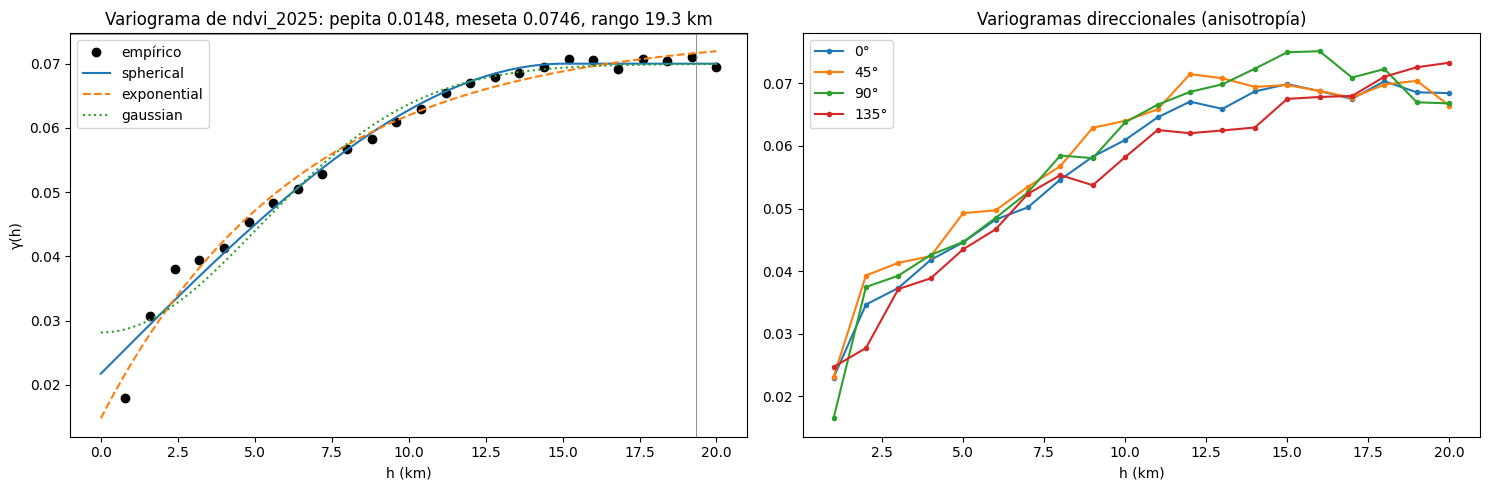

In [0]:
V = modelos[best]["obj"]
h = np.linspace(0, V.bins.max(), 200)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(V.bins, V.experimental, "o", c="k", label="empírico")
for m, sty in zip(modelos, ["-", "--", ":"]):
    ax[0].plot(h, modelos[m]["obj"].fitted_model(h), sty, label=m)
r, ps, n0 = modelos[best]["rango_km"], modelos[best]["meseta_parcial"], modelos[best]["pepita"]
ax[0].axhline(ps + n0, c="grey", lw=0.6); ax[0].axvline(r, c="grey", lw=0.6)
ax[0].set_xlabel("h (km)"); ax[0].set_ylabel("γ(h)"); ax[0].legend()
ax[0].set_title(f"Variograma de {VAR}: pepita {n0:.4f}, meseta {ps+n0:.4f}, rango {r:.1f} km")

for az, c in [(0, "C0"), (45, "C1"), (90, "C2"), (135, "C3")]:
    DV = skg.DirectionalVariogram(coords, vals, azimuth=az, tolerance=22.5, n_lags=20, maxlag=20)
    ax[1].plot(DV.bins, DV.experimental, "o-", c=c, ms=3, label=f"{az}°")
ax[1].set_xlabel("h (km)"); ax[1].set_title("Variogramas direccionales (anisotropía)"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "04_variogramas.png", dpi=150); plt.show()

**Lectura:** la pepita mide la variación a escala menor que un hexágono más el error de medición;
el rango es la distancia a partir de la cual dos hexágonos ya no se parecen. Si los variogramas
direccionales alcanzan mesetas distintas, hay anisotropía alineada con la red fluvial.

## 2. Validación: kriging ordinario vs IDW (20 % de retención)

In [0]:
from pykrige.ok import OrdinaryKriging
from scipy.spatial import cKDTree

km = best if best in ("spherical", "exponential") else "spherical"
p = modelos[km]
vparams = {"sill": p["meseta_total"], "range": p["rango_km"], "nugget": p["pepita"]}

train = obs.iloc[rng.choice(len(obs), size=min(6000, len(obs)), replace=False)]
idx = rng.permutation(len(train)); cut = int(0.8 * len(train))
tr, te = train.iloc[idx[:cut]], train.iloc[idx[cut:]]

ok = OrdinaryKriging(tr.x_km, tr.y_km, tr[VAR], variogram_model=km, variogram_parameters=vparams)
z_ok, ss_ok = ok.execute("points", te.x_km.values, te.y_km.values, backend="loop", n_closest_points=50)

tree = cKDTree(tr[["x_km", "y_km"]].values)
dd, ii = tree.query(te[["x_km", "y_km"]].values, k=12)
wts = 1 / np.maximum(dd, 1e-6) ** 2
z_idw = (wts * tr[VAR].values[ii]).sum(1) / wts.sum(1)

def met(z, zhat):
    e = zhat - z
    return {"RMSE": np.sqrt(np.mean(e**2)), "MAE": np.mean(np.abs(e)), "R2": 1 - np.sum(e**2) / np.sum((z - z.mean())**2)}
cv = pd.DataFrame({"Kriging ordinario": met(te[VAR].values, np.asarray(z_ok)),
                   "IDW (p=2, k=12)": met(te[VAR].values, z_idw)}).T
print(cv.round(4))

                     RMSE     MAE      R2
Kriging ordinario  0.1375  0.0820  0.7009
IDW (p=2, k=12)    0.1317  0.0764  0.7253


## 3. Relleno de vacíos y mapa de incertidumbre

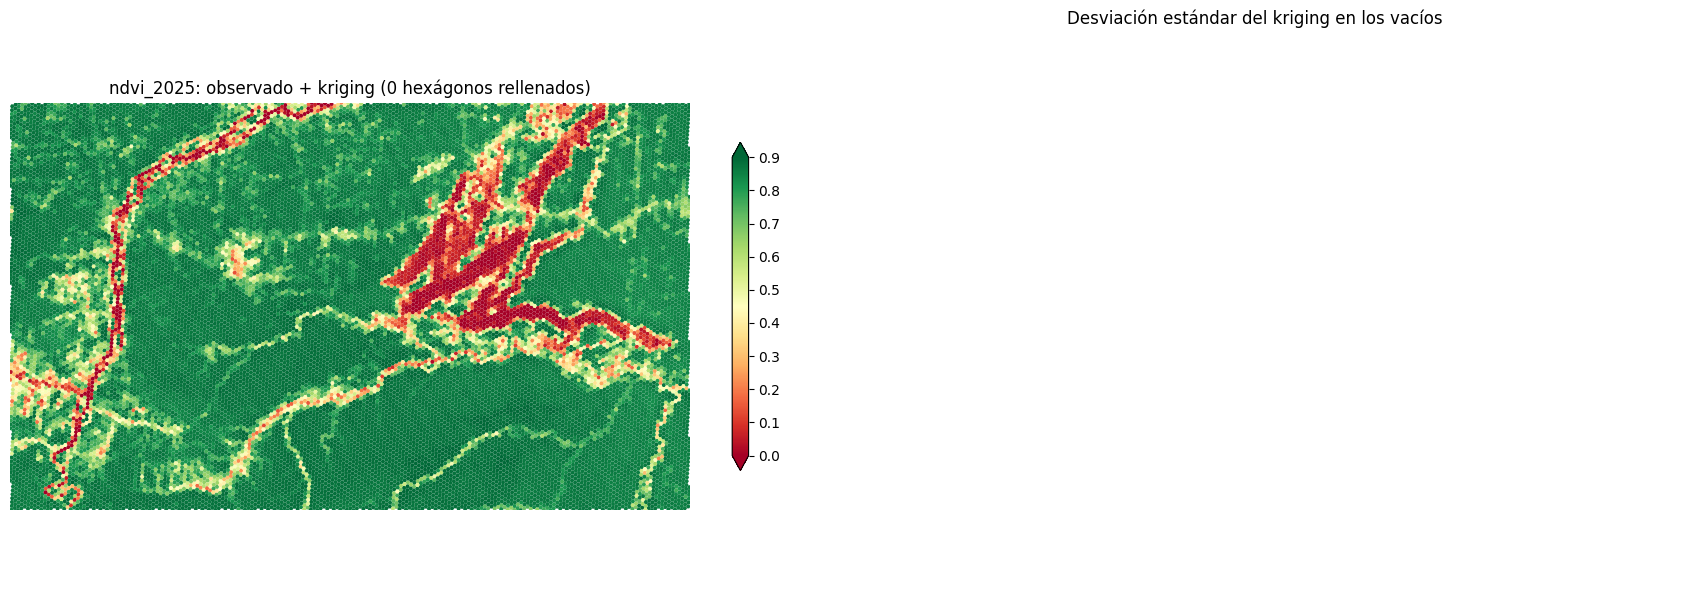

'workspace.madre_dios_rs.gold_h3_ndvi_kriging'

In [0]:
if len(gaps):
    zg, sg = ok.execute("points", gaps.x_km.values, gaps.y_km.values, backend="loop", n_closest_points=50)
    gaps[VAR + "_krig"], gaps["krig_sd"] = np.asarray(zg), np.sqrt(np.asarray(sg))
full = pd.concat([obs.assign(**{VAR + "_krig": obs[VAR], "krig_sd": 0.0, "origen": "observado"}),
                  gaps.assign(origen="kriging")], ignore_index=True)
full = gpd.GeoDataFrame(full, geometry="geometry", crs=C.CRS_UTM)

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
full.plot(column=VAR + "_krig", cmap="RdYlGn", vmin=0, vmax=0.9, linewidth=0, ax=ax[0], legend=True,
          legend_kwds={"shrink": 0.6})
ax[0].set_title(f"{VAR}: observado + kriging ({len(gaps):,} hexágonos rellenados)")
full[full.origen == "kriging"].plot(column="krig_sd", cmap="magma_r", linewidth=0, ax=ax[1], legend=True,
                                    legend_kwds={"shrink": 0.6})
ax[1].set_title("Desviación estándar del kriging en los vacíos")
for a in ax:
    a.set_xlim(C.GRID_BOUNDS_UTM[0], C.GRID_BOUNDS_UTM[2]); a.set_ylim(C.GRID_BOUNDS_UTM[1], C.GRID_BOUNDS_UTM[3]); a.set_axis_off()
plt.tight_layout(); plt.savefig(FIG / "04_kriging.png", dpi=150); plt.show()

dbx.save_table(spark.createDataFrame(pd.DataFrame(full[["h3", VAR + "_krig", "krig_sd", "origen"]])),
               "gold_h3_ndvi_kriging")